# Exploración de Bank Marketing y validación de calidad
Ejecutar todas las celdas en orden desde un kernel nuevo. Primero se busca `data/bank-full.csv`, recuperable con `dvc pull`. Si no existe, se descarga el archivo oficial de UCI y se comprueban su tamaño y MD5 contra `data/bank-full.csv.dvc` antes de leerlo. Una discrepancia detiene la ejecución.

Las cuatro gráficas del informe se regeneran en `docs/figuras/`. Las comprobaciones de conteos corresponden a esta versión concreta del dataset; si se versionan nuevos datos, deben revisarse sus valores esperados.

In [1]:
import pandas as pd
import requests
import zipfile
import io
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re
import hashlib
from scipy.stats import gaussian_kde
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [2]:
# Localizar el repositorio y leer la referencia versionada por DVC.
# En Colab: abrir este notebook desde una copia clonada del repositorio,
# o situar el directorio de trabajo dentro de esa copia.
candidatos = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "priorizacion-clientes-cdt"]
raiz_proyecto = next(
    (p for p in candidatos if (p / "data/bank-full.csv.dvc").is_file()), None
)
if raiz_proyecto is None:
    raise FileNotFoundError("No se encontró data/bank-full.csv.dvc. Clone el repositorio y ejecute desde su carpeta.")

referencia_dvc = raiz_proyecto / "data/bank-full.csv.dvc"
metadatos_dvc = referencia_dvc.read_text(encoding="utf-8-sig")
coincidencia_hash = re.search(r"^\s*-?\s*md5:\s*([a-f0-9]{32})\s*$", metadatos_dvc, re.MULTILINE)
coincidencia_size = re.search(r"^\s*size:\s*(\d+)\s*$", metadatos_dvc, re.MULTILINE)
if coincidencia_hash is None or coincidencia_size is None:
    raise ValueError("La referencia DVC debe declarar md5 y size para verificar el dataset.")
md5_esperado = coincidencia_hash.group(1)
tamano_esperado = int(coincidencia_size.group(1))
ruta_dataset = raiz_proyecto / "data/bank-full.csv"
ruta_figuras = raiz_proyecto / "docs/figuras"
ruta_figuras.mkdir(parents=True, exist_ok=True)

In [3]:
# Buscar el CSV dentro del ZIP principal o de los ZIP internos
def buscar_csv(contenido, nombres_preferidos):
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        archivos = z.namelist()

        # Buscar primero bank-full.csv y luego bank.csv
        for nombre_objetivo in nombres_preferidos:
            for nombre in archivos:
                if nombre.lower().endswith(nombre_objetivo.lower()):
                    datos = z.read(nombre)
                    return datos, nombre

        # Si hay ZIP internos, buscar también dentro de ellos
        for nombre in archivos:
            if nombre.lower().endswith(".zip"):
                resultado = buscar_csv(
                    z.read(nombre),
                    nombres_preferidos
                )
                if resultado is not None:
                    return resultado

    return None

# Preferir el archivo recuperado mediante dvc pull. Si no está disponible,
# descargar UCI y exigir que coincida exactamente con la versión de DVC.
if ruta_dataset.is_file():
    contenido_csv = ruta_dataset.read_bytes()
    archivo_encontrado = str(ruta_dataset.relative_to(raiz_proyecto))
    origen_dataset = "Archivo local versionado con DVC"
else:
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    resultado = buscar_csv(response.content, ["bank-full.csv"])
    if resultado is None:
        raise FileNotFoundError("No se encontró bank-full.csv en el ZIP oficial de UCI.")
    contenido_csv, archivo_encontrado = resultado
    origen_dataset = "Descarga oficial UCI verificada contra DVC"

md5_observado = hashlib.md5(contenido_csv).hexdigest()
if md5_observado != md5_esperado or len(contenido_csv) != tamano_esperado:
    raise ValueError(
        f"El dataset no coincide con DVC: md5={md5_observado}, bytes={len(contenido_csv)}. "
        "Recupere la versión correcta mediante dvc pull."
    )
if not ruta_dataset.is_file():
    ruta_dataset.parent.mkdir(parents=True, exist_ok=True)
    ruta_dataset.write_bytes(contenido_csv)
print("Origen:", origen_dataset)
print("Integridad DVC verificada; MD5:", md5_observado)

# El CSV de UCI usa punto y coma como separador
df = pd.read_csv(
    io.BytesIO(contenido_csv),
    sep=";",
    na_values=["NA", ""]
)

print("Archivo cargado:", archivo_encontrado)
print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 10 filas:")
display(df.head(10))

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo_de_dato"))

print("\nValores faltantes por columna:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("valores_faltantes")
)

print("\nDistribución de la variable objetivo (y):")
display(df["y"].value_counts(dropna=False).to_frame("cantidad"))

print("\nPorcentaje de cada clase:")
display(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("porcentaje")
)

Origen: Archivo local versionado con DVC
Integridad DVC verificada; MD5: e6b0ca77f3f200ec5428e04dd104da53
Archivo cargado: data\bank-full.csv
Dimensiones: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 10 filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no



Tipos de datos:


,tipo_de_dato
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Valores faltantes por columna:


,valores_faltantes
age,0
day,0
poutcome,0
previous,0
pdays,0
campaign,0
duration,0
month,0
contact,0
job,0



Distribución de la variable objetivo (y):


,cantidad
y,
no,39922
yes,5289



Porcentaje de cada clase:


,porcentaje
y,
no,88.3
yes,11.7


In [4]:
# Normalizar cadenas vacías como valores ausentes reales
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 5 filas:")
display(df.head())

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nDuplicados exactos:", df.duplicated().sum())

Dimensiones: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 5 filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Tipos de datos:


,tipo
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Duplicados exactos: 0


In [5]:
# Resumen de valores ausentes
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_ausentes": df.isna().sum(),
    "porcentaje_ausente": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
}).sort_values("porcentaje_ausente", ascending=False)

display(calidad)

,tipo,valores_ausentes,porcentaje_ausente,valores_unicos
age,int64,0,0.0,77
day,int64,0,0.0,31
poutcome,object,0,0.0,4
previous,int64,0,0.0,41
pdays,int64,0,0.0,559
campaign,int64,0,0.0,48
duration,int64,0,0.0,1573
month,object,0,0.0,12
contact,object,0,0.0,3
job,object,0,0.0,12


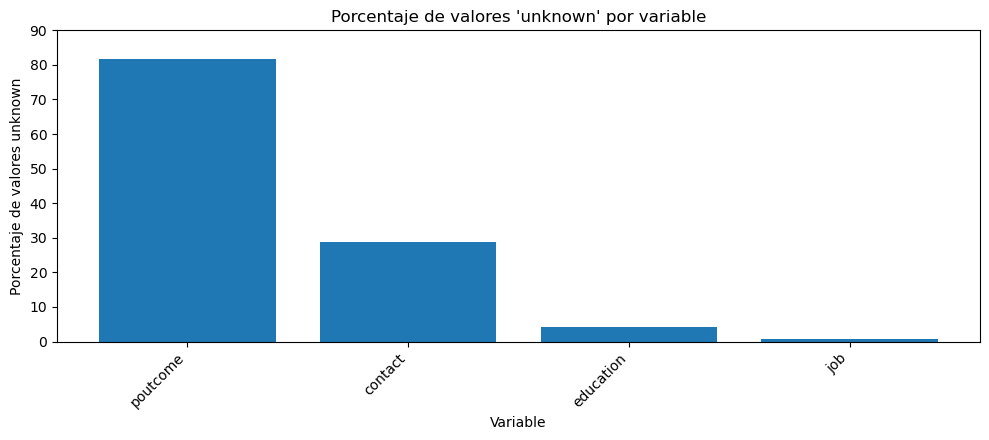

In [6]:
# Diagnóstico de valores ausentes reales y categorías unknown

# Contar los valores unknown por variable
total_registros = len(df)

conteo_unknown = pd.Series({
    col: df[col].astype("string").str.strip().str.lower().eq("unknown").sum()
    for col in df.columns
})

# Calcular porcentaje y conservar solo variables con unknown
porcentaje_unknown = (
    conteo_unknown[conteo_unknown > 0] / total_registros * 100
).sort_values(ascending=False)

# Gráfica con el estilo original
plt.figure(figsize=(10, 4.5))

plt.bar(
    porcentaje_unknown.index,
    porcentaje_unknown.values,
    color="tab:blue"
)

plt.title("Porcentaje de valores 'unknown' por variable")
plt.xlabel("Variable")
plt.ylabel("Porcentaje de valores unknown")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 90)

plt.tight_layout()
plt.show()   

,cantidad,porcentaje
y,,
no,39922,88.3
yes,5289,11.7


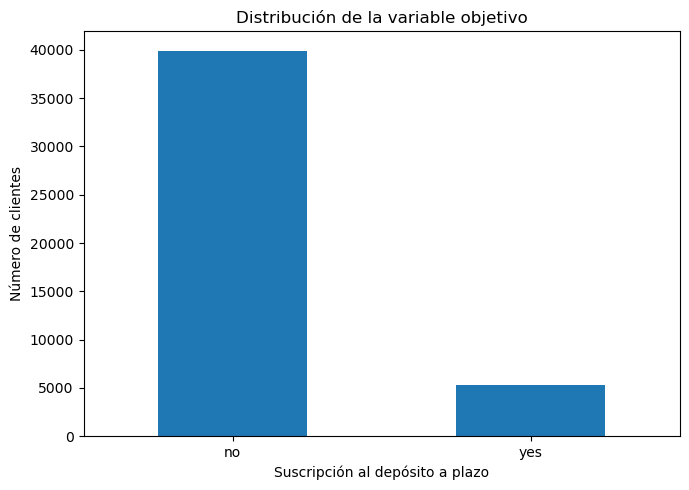

In [7]:
conteo_y = df["y"].value_counts()
porcentaje_y = df["y"].value_counts(normalize=True) * 100

resumen_y = pd.DataFrame({
    "cantidad": conteo_y,
    "porcentaje": porcentaje_y.round(2)
})

display(resumen_y)

plt.figure(figsize=(7, 5))
conteo_y.plot(kind="bar")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Suscripción al depósito a plazo")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Interpretación: desbalance de la variable objetivo
De los 45.211 registros, 5.289 (11,70 %) corresponden a `yes` y 39.922 (88,30 %) a `no`. Predecir siempre `no` alcanzaría una exactitud del 88,30 % sin identificar ninguna suscripción. Durante el modelado se evaluarán precisión, recall, F1, matriz de confusión y la curva precisión-recall; la exactitud aislada no será suficiente. Estas cifras describen la muestra histórica y no una probabilidad garantizada para nuevos clientes.

## Análisis de cada variable

### Análisis de las variables numéricas

Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


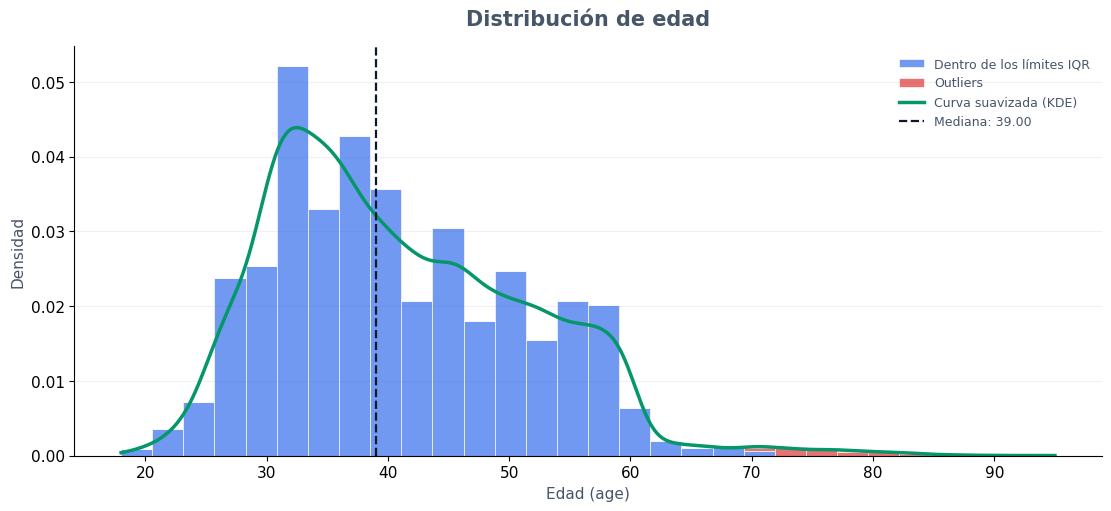

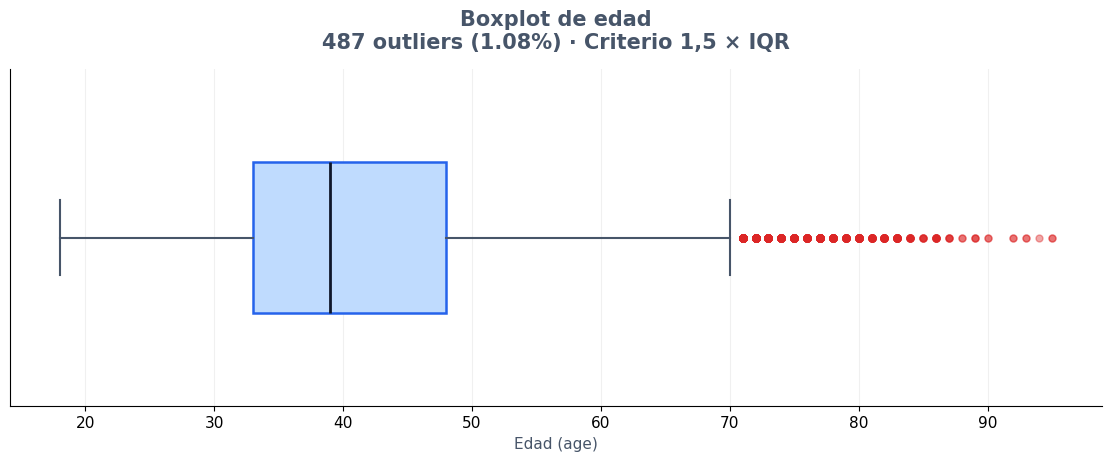

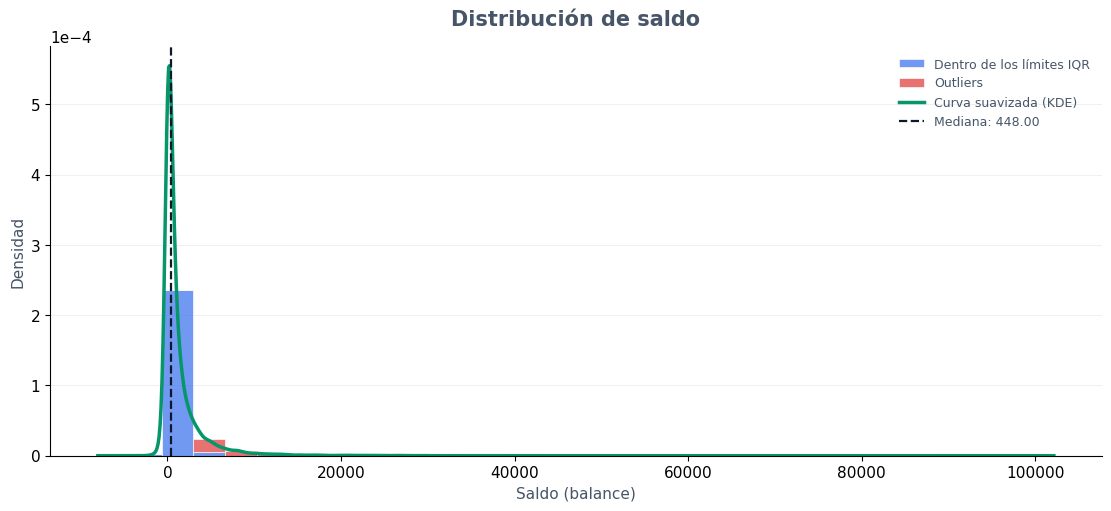

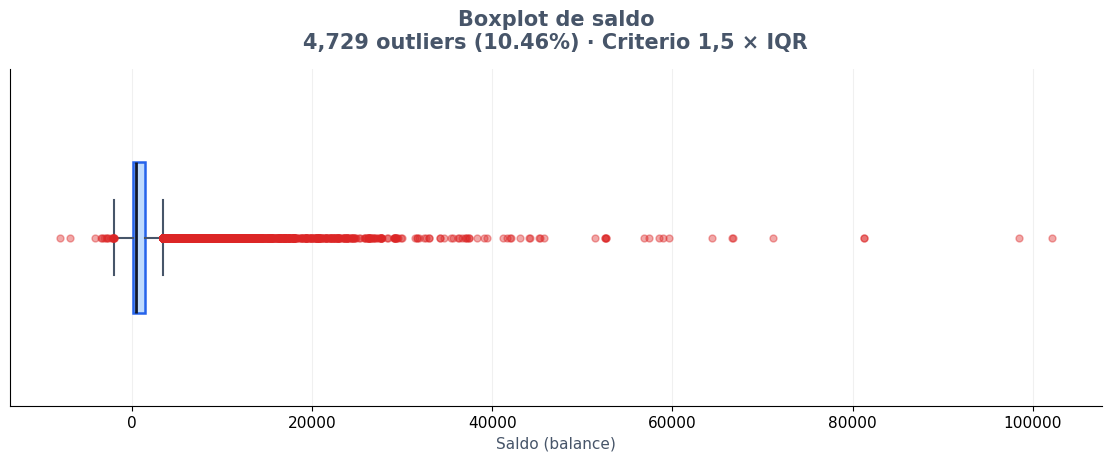

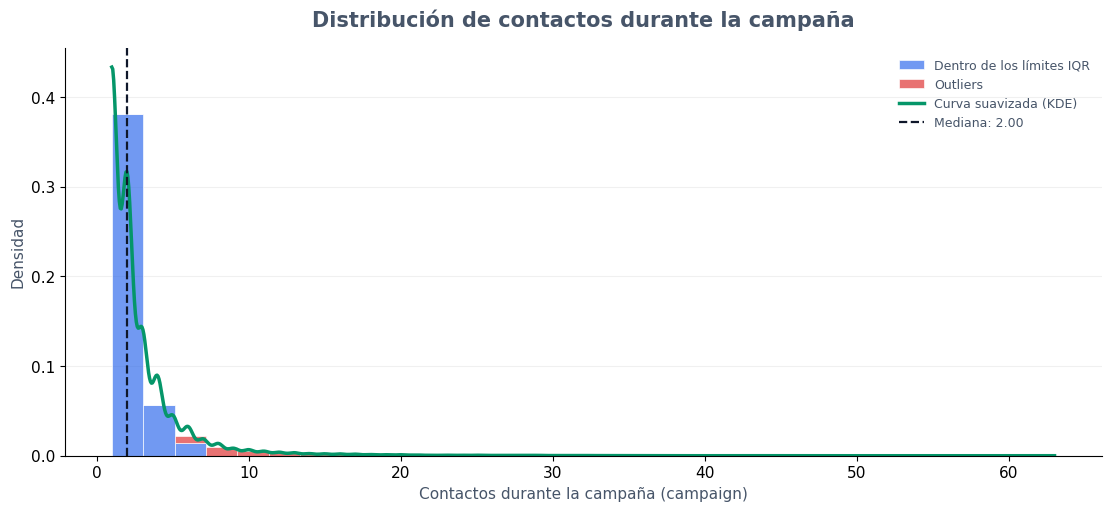

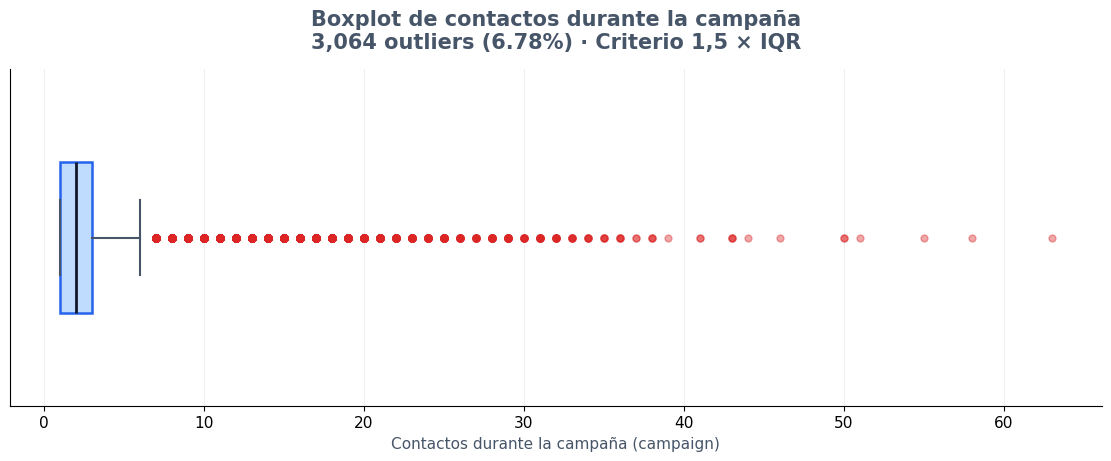

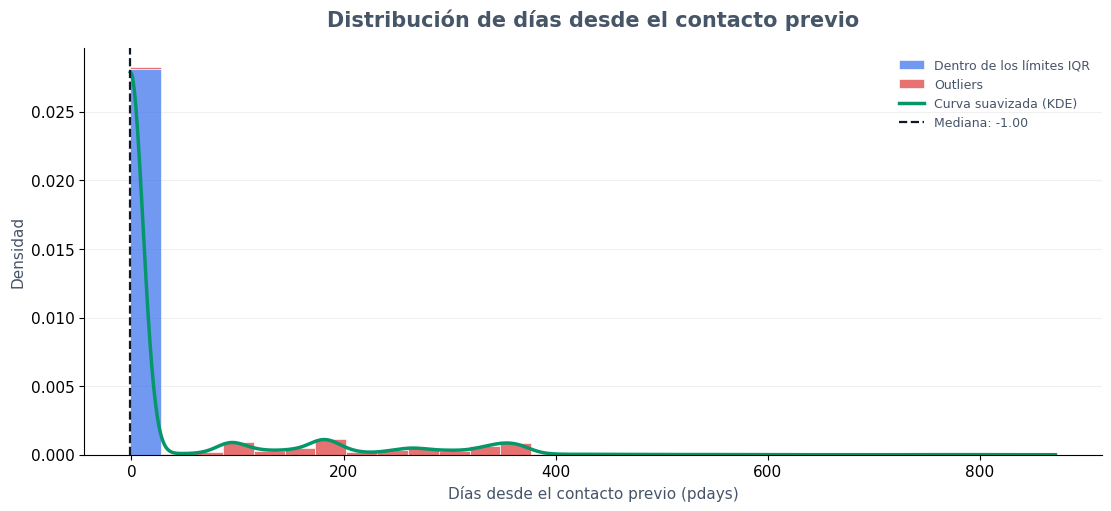

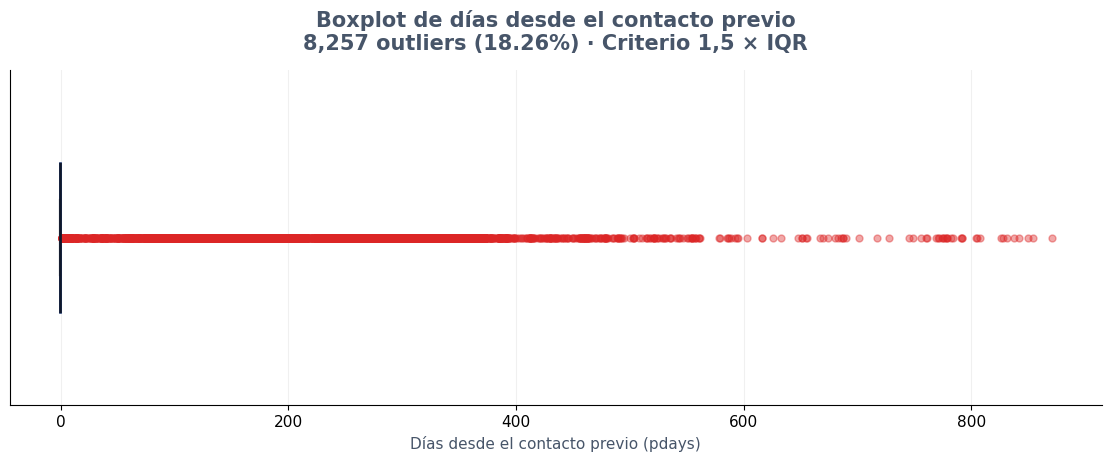

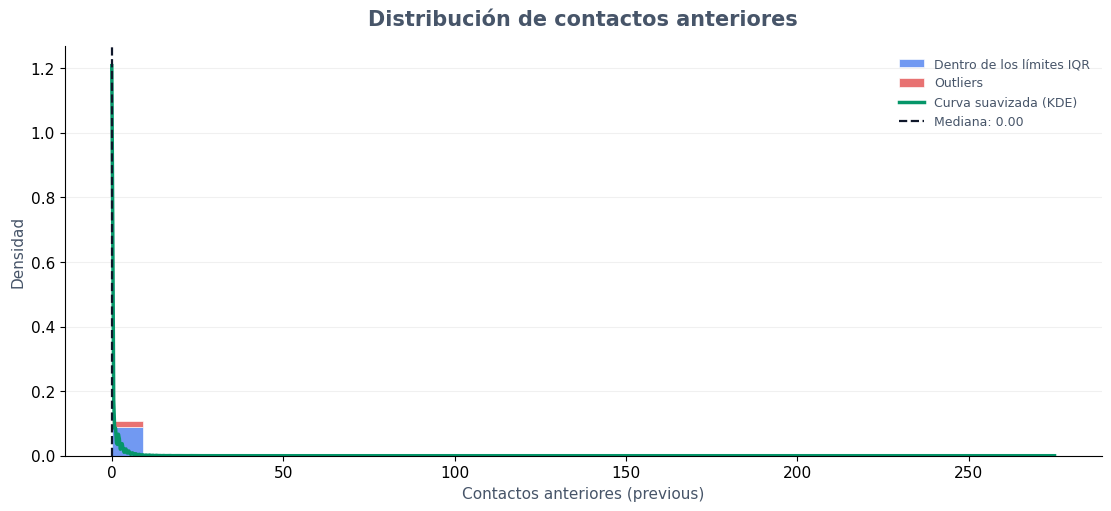

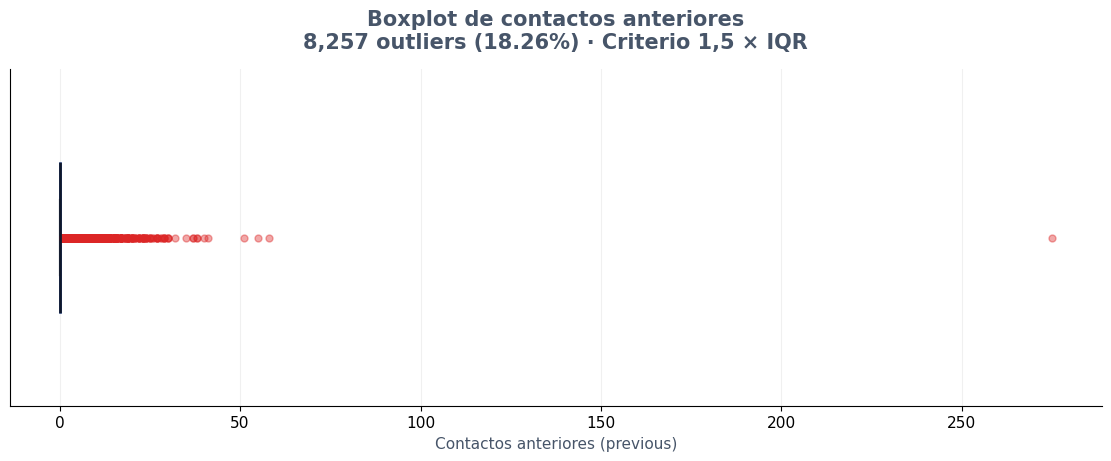

Resumen de valores atípicos:


,Variable,Observaciones,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers,% outliers
0,age,45211,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,45211,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,campaign,45211,1.0,3.0,2.0,-2.0,6.0,3064,6.78
3,pdays,45211,-1.0,-1.0,0.0,-1.0,-1.0,8257,18.26
4,previous,45211,0.0,0.0,0.0,0.0,0.0,8257,18.26


In [8]:
# 1. Estadísticas descriptivas
numericas = df.select_dtypes(include="number")

print("Estadísticas descriptivas:")
display(numericas.describe().T.round(2))

# Variables que vamos a analizar
variables = ["age", "balance", "campaign", "pdays", "previous"]

etiquetas = {
    "age": "Edad",
    "balance": "Saldo",
    "campaign": "Contactos durante la campaña",
    "pdays": "Días desde el contacto previo",
    "previous": "Contactos anteriores"
}

# Colores
AZUL = "#2563EB"
AZUL_CLARO = "#BFDBFE"
ROJO = "#DC2626"
VERDE = "#059669"
GRIS = "#475569"

resumen_outliers = []
outliers_por_variable = {}

estilo = {
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelcolor": GRIS,
    "text.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
}

for variable in variables:
    if variable not in df.columns:
        continue

    valores = (
        pd.to_numeric(df[variable], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if valores.empty:
        continue

    nombre = etiquetas.get(variable, variable)

    # 2. Detección de outliers mediante 1,5 × IQR
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara_outliers = (
        (valores < limite_inferior)
        | (valores > limite_superior)
    )

    atipicos = valores[mascara_outliers]
    porcentaje = len(atipicos) / len(valores) * 100
    mediana = valores.median()

    outliers_por_variable[variable] = (
        atipicos.sort_values().to_frame(name=variable)
    )

    resumen_outliers.append({
        "Variable": variable,
        "Observaciones": len(valores),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Outliers": len(atipicos),
        "% outliers": porcentaje
    })

    with plt.rc_context(estilo):

        # 3. FIGURA INDEPENDIENTE: distribución y curva KDE
        fig, ax = plt.subplots(
            figsize=(11, 5),
            constrained_layout=True
        )

        bordes = np.histogram_bin_edges(valores, bins=30)

        # Densidad para que histograma y KDE usen la misma escala
        ax.hist(
            [valores[~mascara_outliers], atipicos],
            bins=bordes,
            stacked=True,
            density=True,
            color=[AZUL, ROJO],
            alpha=0.65,
            edgecolor="white",
            linewidth=0.7,
            label=["Dentro de los límites IQR", "Outliers"]
        )

        # KDE: requiere al menos dos valores diferentes
        if valores.nunique() > 1:
            kde = gaussian_kde(valores.to_numpy())

            eje_x = np.linspace(
                valores.min(),
                valores.max(),
                1000
            )

            ax.plot(
                eje_x,
                kde(eje_x),
                color=VERDE,
                linewidth=2.5,
                label="Curva suavizada (KDE)"
            )

        ax.axvline(
            mediana,
            color="#0F172A",
            linestyle="--",
            linewidth=1.6,
            label=f"Mediana: {mediana:,.2f}"
        )

        ax.set_title(f"Distribución de {nombre.lower()}", pad=15)
        ax.set_xlabel(f"{nombre} ({variable})")
        ax.set_ylabel("Densidad")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.18)
        ax.legend(frameon=False, fontsize=9)
        ax.ticklabel_format(
            axis="y", style="sci", scilimits=(-3, 3)
        )

        plt.show()

        # 4. Boxplot
        fig, ax = plt.subplots(
            figsize=(11, 4.5),
            constrained_layout=True
        )

        ax.boxplot(
            valores.to_numpy(),
            vert=False,
            widths=0.45,
            whis=1.5,
            patch_artist=True,
            showfliers=True,
            boxprops={
                "facecolor": AZUL_CLARO,
                "edgecolor": AZUL,
                "linewidth": 1.8
            },
            medianprops={
                "color": "#0F172A",
                "linewidth": 2
            },
            whiskerprops={
                "color": GRIS,
                "linewidth": 1.5
            },
            capprops={
                "color": GRIS,
                "linewidth": 1.5
            },
            flierprops={
                "marker": "o",
                "markerfacecolor": ROJO,
                "markeredgecolor": ROJO,
                "markersize": 5,
                "alpha": 0.4
            }
        )

        ax.set_title(
            f"Boxplot de {nombre.lower()}\n"
            f"{len(atipicos):,} outliers "
            f"({porcentaje:.2f}%) · Criterio 1,5 × IQR",
            pad=15
        )

        ax.set_xlabel(f"{nombre} ({variable})")
        ax.set_yticks([])
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.18)

        plt.show()

# 5. Tabla resumen de outliers
resumen_outliers = pd.DataFrame(resumen_outliers)

print("Resumen de valores atípicos:")
display(resumen_outliers.round(2))

### Interpretación: valores atípicos y códigos especiales
El criterio de 1,5 × IQR identifica 487 registros en `age` (1,08 %), 4.729 en `balance` (10,46 %) y 3.064 en `campaign` (6,78 %). Son señales para revisar las distribuciones, no una justificación automática para eliminar observaciones.

En `pdays`, Q1 = Q3 = -1; en `previous`, Q1 = Q3 = 0. Por tanto, el IQR es cero y los límites colapsan a esos valores. El método marca 8.257 registros (18,26 %) en cada variable, correspondientes a valores distintos de su categoría dominante. `pdays = -1` representa ausencia de contacto en campañas anteriores y `previous = 0` indica cero contactos previos. Los registros restantes no son necesariamente errores ni deben eliminarse por esta etiqueta estadística. Conviene estudiar por separado la presencia de contacto previo y, entre quienes lo tuvieron, la distribución de los días y del número de contactos. Se conservan los datos originales.

### Análisis de las variables categóricas

In [9]:
categoricas = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for variable in categoricas:
    serie = df[variable]
    total = len(serie)

    # Identificar "unknown", ignorando mayúsculas y espacios
    es_unknown = (
        serie.astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .fillna(False)
    )

    # Moda incluyendo "unknown", pero excluyendo valores nulos
    modas_con_unknown = serie.mode(dropna=True)

    # Moda excluyendo tanto "unknown" como los valores nulos
    valores_conocidos = serie[~es_unknown].dropna()
    modas_sin_unknown = valores_conocidos.mode(dropna=True)

    # Frecuencias sobre el total de registros, incluidos los nulos
    tabla = (
        serie.value_counts(dropna=False)
        .rename_axis("Categoría")
        .reset_index(name="Frecuencia absoluta")
    )

    tabla["Frecuencia relativa"] = (
        tabla["Frecuencia absoluta"] / total if total else 0.0
    )

    tabla["Porcentaje (%)"] = (
        tabla["Frecuencia relativa"] * 100
    )

    # Marcar todas las categorías modales si existe empate
    for columna, modas in [
        ("Moda con unknown", modas_con_unknown),
        ("Moda sin unknown", modas_sin_unknown)
    ]:
        if modas.empty:
            tabla[columna] = "No aplica"
        else:
            es_moda = (
                tabla["Categoría"].notna()
                & tabla["Categoría"].isin(modas.tolist())
            )

            tabla[columna] = np.where(es_moda, "Sí", "No")

    # Etiqueta para los nulos, distinta de la categoría "unknown"
    tabla["Categoría"] = (
        tabla["Categoría"]
        .astype("object")
        .where(tabla["Categoría"].notna(), "(Faltante)")
    )

    print(f"\nDistribución de {variable}:")

    display(
        tabla.style.format({
            "Frecuencia absoluta": "{:,.0f}",
            "Frecuencia relativa": "{:.4f}",
            "Porcentaje (%)": "{:.2f}"
        })
    )


Distribución de job:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,blue-collar,"9,732",0.2153,21.53,Sí,Sí
1,management,"9,458",0.2092,20.92,No,No
2,technician,"7,597",0.1680,16.80,No,No
3,admin.,"5,171",0.1144,11.44,No,No
4,services,"4,154",0.0919,9.19,No,No
5,retired,"2,264",0.0501,5.01,No,No
6,self-employed,"1,579",0.0349,3.49,No,No
7,entrepreneur,"1,487",0.0329,3.29,No,No
8,unemployed,"1,303",0.0288,2.88,No,No
9,housemaid,"1,240",0.0274,2.74,No,No



Distribución de marital:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,married,"27,214",0.6019,60.19,Sí,Sí
1,single,"12,790",0.2829,28.29,No,No
2,divorced,"5,207",0.1152,11.52,No,No



Distribución de education:


...

,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,may,"13,766",0.3045,30.45,Sí,Sí
1,jul,"6,895",0.1525,15.25,No,No
2,aug,"6,247",0.1382,13.82,No,No
3,jun,"5,341",0.1181,11.81,No,No
4,nov,"3,970",0.0878,8.78,No,No
5,apr,"2,932",0.0649,6.49,No,No
6,feb,"2,649",0.0586,5.86,No,No
7,jan,"1,403",0.0310,3.10,No,No
8,oct,738,0.0163,1.63,No,No
9,sep,579,0.0128,1.28,No,No



Distribución de poutcome:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,unknown,"36,959",0.8175,81.75,Sí,No
1,failure,"4,901",0.1084,10.84,No,Sí
2,other,"1,840",0.0407,4.07,No,No
3,success,"1,511",0.0334,3.34,No,No



Distribución de y:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,no,"39,922",0.8830,88.30,Sí,Sí
1,yes,"5,289",0.1170,11.70,No,No


### Interpretación: frecuencias y modas
Las frecuencias incluyen los nulos, mientras que las modas se calculan excluyéndolos. Se muestran modas con y sin `unknown` para evitar que una categoría de información no especificada o de antecedentes no conocidos oculte las categorías conocidas. La normalización de espacios y mayúsculas se usa para detectar `unknown`; no recodifica los valores originales ni imputa categorías.


Porcentaje de suscripción por job:


y,no,yes
job,,
student,71.32,28.68
retired,77.21,22.79
unemployed,84.50,15.50
management,86.24,13.76
admin.,87.80,12.20
self-employed,88.16,11.84
unknown,88.19,11.81
technician,88.94,11.06
services,91.12,8.88


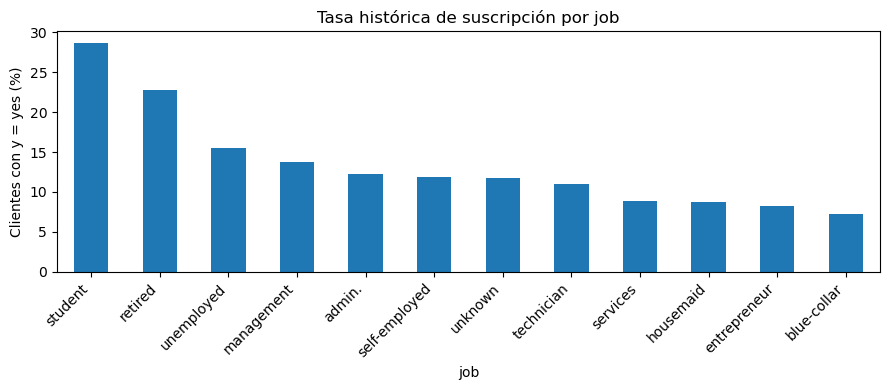


Porcentaje de suscripción por marital:


y,no,yes
marital,,
single,85.05,14.95
divorced,88.05,11.95
married,89.88,10.12


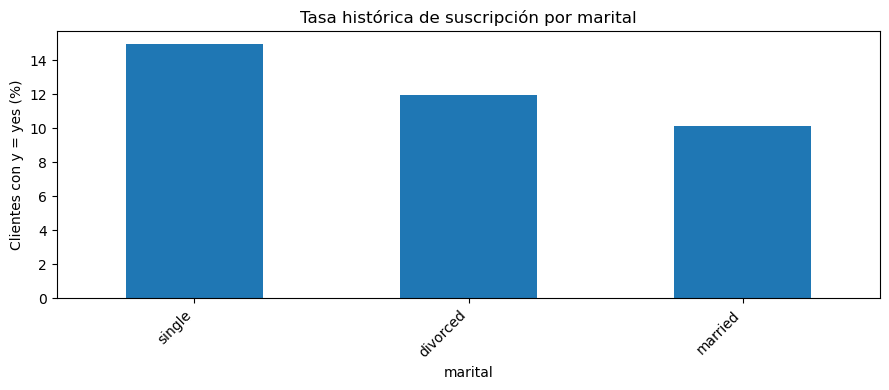


Porcentaje de suscripción por education:


y,no,yes
education,,
tertiary,84.99,15.01
unknown,86.43,13.57
secondary,89.44,10.56
primary,91.37,8.63


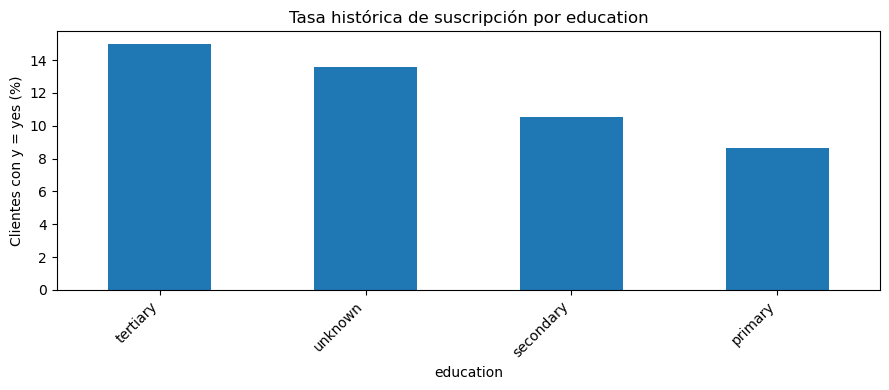


Porcentaje de suscripción por housing:


y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


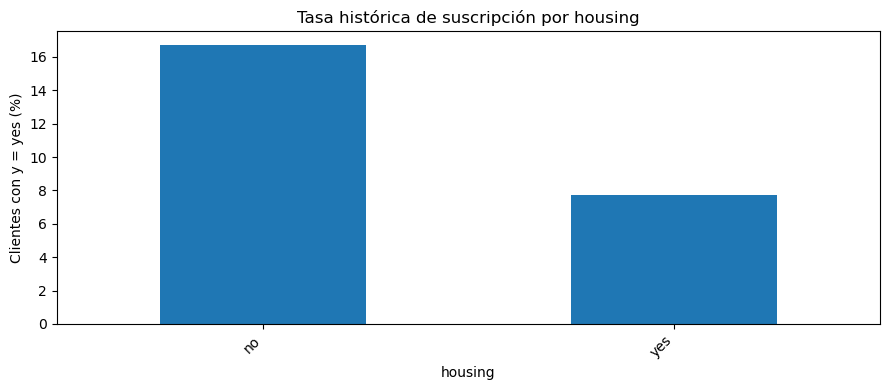


Porcentaje de suscripción por loan:


y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


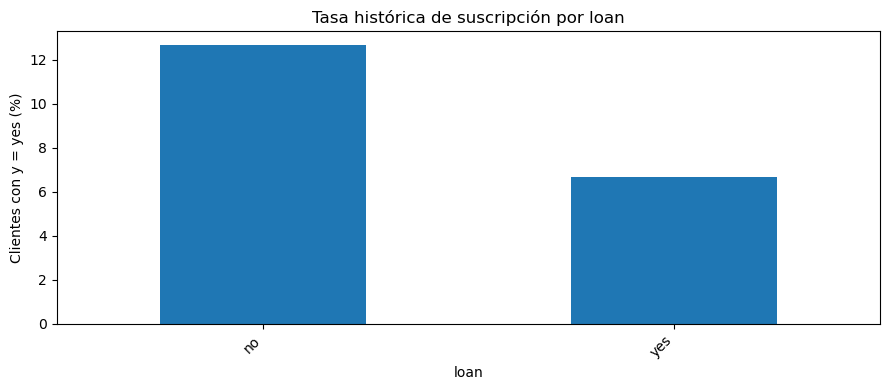


Porcentaje de suscripción por contact:


y,no,yes
contact,,
cellular,85.08,14.92
telephone,86.58,13.42
unknown,95.93,4.07


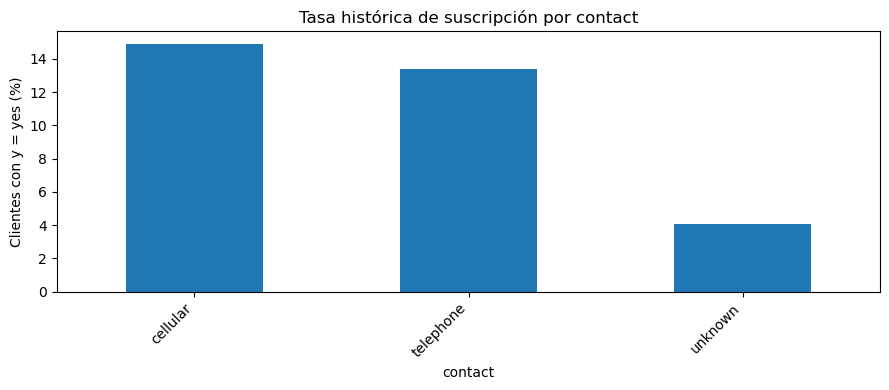


Porcentaje de suscripción por poutcome:


y,no,yes
poutcome,,
success,35.27,64.73
other,83.32,16.68
failure,87.39,12.61
unknown,90.84,9.16


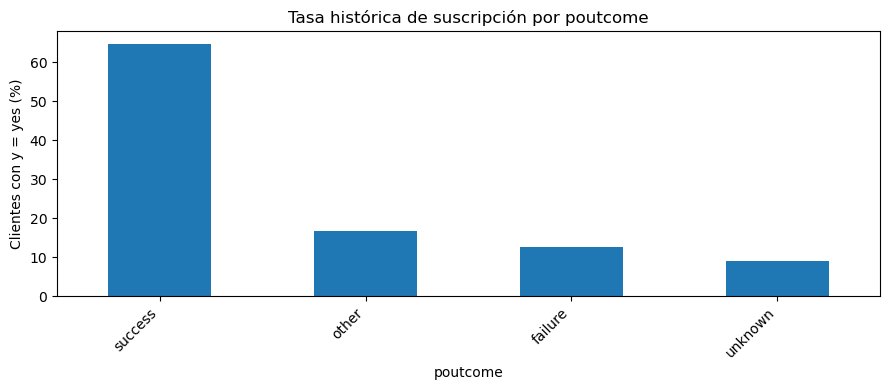

In [10]:
variables_categoricas = [
    "job", "marital", "education",
    "housing", "loan", "contact", "poutcome"
]

for variable in variables_categoricas:
    if variable in df.columns:
        tabla = pd.crosstab(
            df[variable],
            df["y"],
            normalize="index"
        ) * 100

        if "yes" in tabla.columns:
            tabla = tabla.sort_values("yes", ascending=False)

        print(f"\nPorcentaje de suscripción por {variable}:")
        display(tabla.round(2))

        if "yes" in tabla.columns:
            plt.figure(figsize=(9, 4))
            tabla["yes"].plot(kind="bar")
            plt.title(f"Tasa histórica de suscripción por {variable}")
            plt.xlabel(variable)
            plt.ylabel("Clientes con y = yes (%)")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            if variable in {"job", "poutcome"}:
                nombre_figura = {"job": "figura_2_suscripcion_ocupacion.png", "poutcome": "figura_4_suscripcion_campana_anterior.png"}[variable]
                plt.savefig(ruta_figuras / nombre_figura, dpi=180, bbox_inches="tight")
            plt.show()

### Interpretación: asociaciones con la suscripción
Las tasas de suscripción son 28,68 % para `student` y 22,79 % para `retired`, frente al 11,70 % global. Para `poutcome`, son 64,73 % en `success`, 16,68 % en `other`, 12,61 % en `failure` y 9,16 % en `unknown`. Se conserva esta última categoría también en la gráfica. Estas asociaciones no prueban causalidad; el tamaño de cada grupo y la disponibilidad de los antecedentes antes de la predicción deben considerarse al modelar.


Resumen de age según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,40.84,39.0,10.17,18,95
yes,5289,41.67,38.0,13.50,18,95


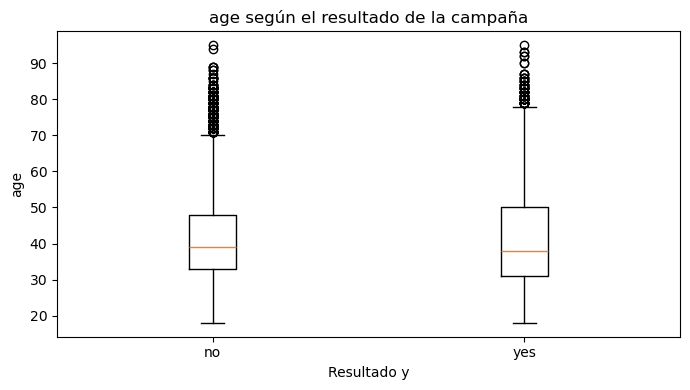


Resumen de balance según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,1303.71,417.0,2974.2,-8019,102127
yes,5289,1804.27,733.0,3501.1,-3058,81204


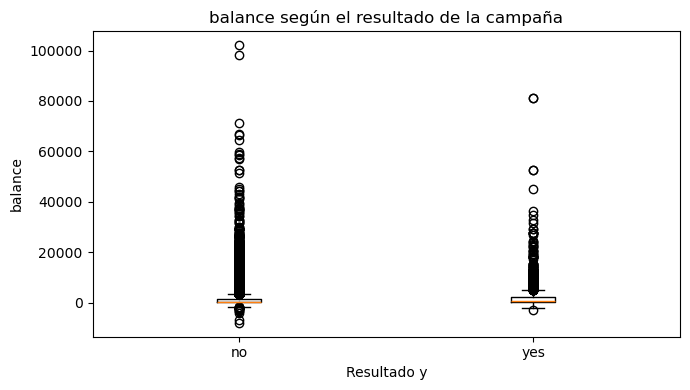


Resumen de campaign según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,2.85,2.0,3.21,1,63
yes,5289,2.14,2.0,1.92,1,32


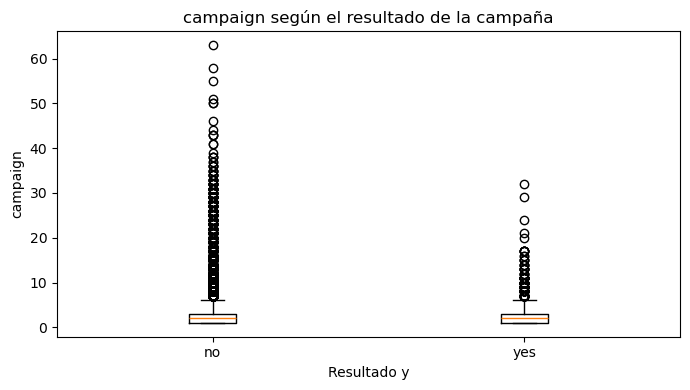


Resumen de previous según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,0.50,0.0,2.26,0,275
yes,5289,1.17,0.0,2.55,0,58


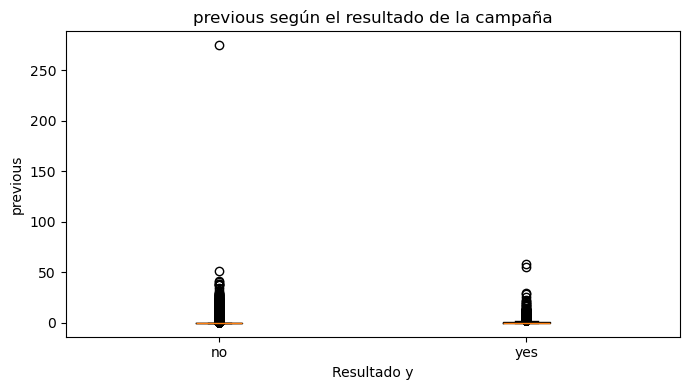


Resumen de duration según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,221.18,164.0,207.38,0,4918
yes,5289,537.29,426.0,392.53,8,3881


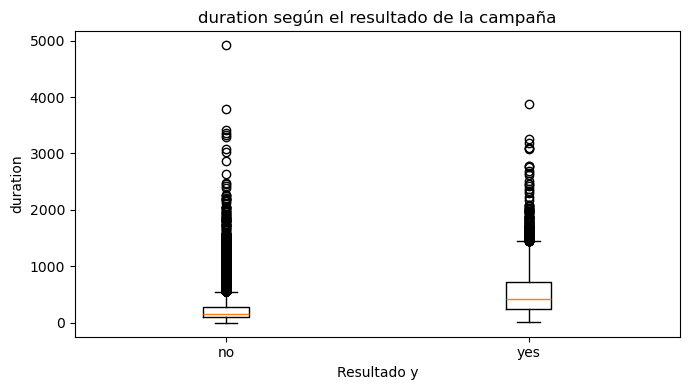

In [11]:
variables_numericas = ["age", "balance", "campaign", "previous", "duration"]

for variable in variables_numericas:
    if variable in df.columns:
        print(f"\nResumen de {variable} según y:")
        display(
            df.groupby("y")[variable]
              .agg(["count", "mean", "median", "std", "min", "max"])
              .round(2)
        )

        grupos = [
            df.loc[df["y"] == clase, variable].dropna()
            for clase in ["no", "yes"]
        ]

        plt.figure(figsize=(7, 4))
        plt.boxplot(grupos, tick_labels=["no", "yes"])
        plt.title(f"{variable} según el resultado de la campaña")
        plt.xlabel("Resultado y")
        plt.ylabel(variable)
        plt.tight_layout()
        if variable == "balance":
            plt.savefig(ruta_figuras / "figura_3_saldo_segun_suscripcion.png", dpi=180, bbox_inches="tight")
        plt.show()

### Interpretación: variables numéricas según el resultado
La edad media es similar entre `no` (40,84) y `yes` (41,67), mientras que el saldo mediano es mayor en `yes` (733 frente a 417). Los extremos del saldo aconsejan evaluar transformaciones o métodos robustos sin asumir que un saldo negativo es un error.

`duration` se presenta exclusivamente para describir el conjunto histórico: no está disponible antes de realizar la llamada y se excluirá de los predictores del modelo de priorización. Las variables de la campaña actual también deben revisarse según el momento exacto en que se realizaría la predicción.

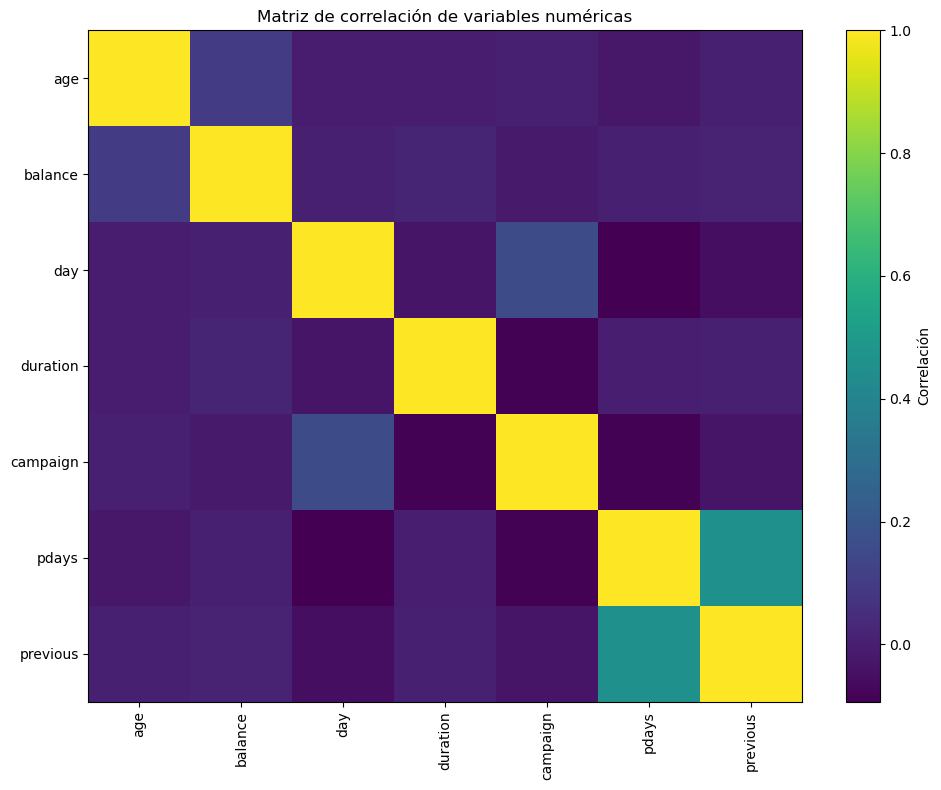

In [12]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto", cmap="viridis")
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

# Diagnóstico de valores faltantes

Se cuentan por separado los NaN y los valores explícitos `unknown`.

In [13]:
total_filas = len(df)

diagnostico_faltantes = pd.DataFrame({
    "variable": df.columns,
    "numero_NaN": df.isna().sum().values,
    "porcentaje_NaN": (
        df.isna().sum().values / total_filas * 100
    ).round(2),
    "numero_unknown": [
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
        for col in df.columns
    ]
})

diagnostico_faltantes = diagnostico_faltantes.sort_values(
    by=["numero_NaN", "numero_unknown"],
    ascending=False
).reset_index(drop=True)

print("Diagnóstico de valores faltantes por variable")
print(f"Número total de registros: {total_filas:,}")
display(diagnostico_faltantes)


Diagnóstico de valores faltantes por variable
Número total de registros: 45,211


,variable,numero_NaN,porcentaje_NaN,numero_unknown
0,poutcome,0,0.0,36959
1,contact,0,0.0,13020
2,education,0,0.0,1857
3,job,0,0.0,288
4,age,0,0.0,0
5,marital,0,0.0,0
6,default,0,0.0,0
7,balance,0,0.0,0
8,housing,0,0.0,0
9,loan,0,0.0,0


In [14]:
# Comprobaciones de la versión bank-full.csv identificada por el hash DVC.
# Fallan explícitamente si se modifica el archivo, la lectura o los conteos esperados.
assert df.shape == (45211, 17), f"Dimensiones inesperadas: {df.shape}"
assert int(df.isna().sum().sum()) == 0, "Se detectaron valores NaN inesperados"
unknown_esperados = {"poutcome": 36959, "contact": 13020, "education": 1857, "job": 288}
unknown_observados = diagnostico_faltantes.set_index("variable")["numero_unknown"].astype(int).to_dict()
for variable in df.columns:
    assert unknown_observados[variable] == unknown_esperados.get(variable, 0), f"Conteo unknown inesperado en {variable}"
assert df["y"].value_counts(dropna=False).to_dict() == {"no": 39922, "yes": 5289}, "Distribución objetivo inesperada"
assert int(df.duplicated().sum()) == 0, "Se detectaron duplicados exactos inesperados"
print("Validación correcta: 45.211 filas, 17 columnas, 0 NaN, 0 duplicados y conteos de unknown/y esperados.")

Validación correcta: 45.211 filas, 17 columnas, 0 NaN, 0 duplicados y conteos de unknown/y esperados.


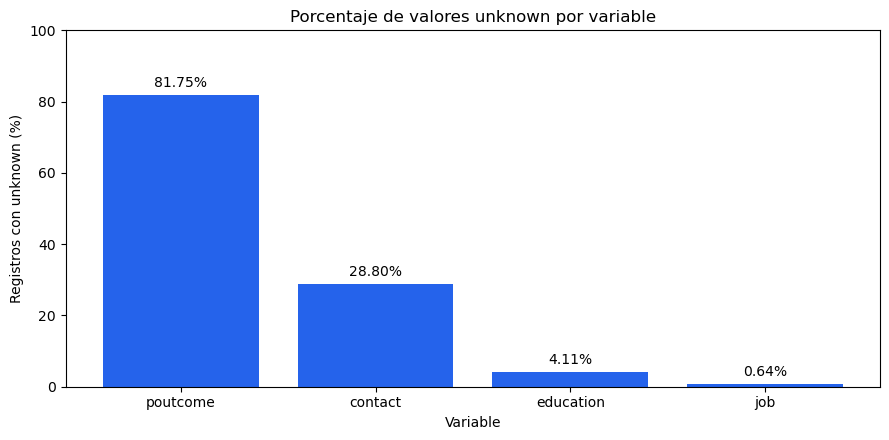

,variable,numero_unknown,porcentaje_unknown
0,poutcome,36959,81.75
1,contact,13020,28.80
2,education,1857,4.11
3,job,288,0.64


In [15]:
# Porcentaje sobre el total de registros; unknown se distingue de NaN.
resumen_unknown = diagnostico_faltantes.loc[
    diagnostico_faltantes["numero_unknown"] > 0, ["variable", "numero_unknown"]
].copy()
resumen_unknown["porcentaje_unknown"] = resumen_unknown["numero_unknown"] / len(df) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(resumen_unknown["variable"], resumen_unknown["porcentaje_unknown"], color="#2563EB")
ax.bar_label(barras, labels=[f"{p:.2f}%" for p in resumen_unknown["porcentaje_unknown"]], padding=4)
ax.set(title="Porcentaje de valores unknown por variable", xlabel="Variable", ylabel="Registros con unknown (%)", ylim=(0, 100))
fig.tight_layout()
fig.savefig(ruta_figuras / "figura_1_porcentaje_unknown.png", dpi=180, bbox_inches="tight")
plt.show()
display(resumen_unknown.round(2))

### Interpretación: calidad y categorías desconocidas
Se verifican cero NaN y cero duplicados exactos. Esto no implica información completamente especificada: `unknown` aparece en `poutcome` (36.959; 81,75 %), `contact` (13.020; 28,80 %), `education` (1.857; 4,11 %) y `job` (288; 0,64 %).

Se conserva `unknown` como categoría explícita; no se eliminan registros ni se imputa automáticamente. En `poutcome` debe distinguirse de la ausencia de contacto previo usando `pdays` y `previous`: sus conteos son próximos pero no idénticos. Los tratamientos definitivos se decidirán durante el modelado y se ajustarán solo con los datos de entrenamiento.

## Revisión específica: contact, education, job y poutcome

In [16]:
variables_prioritarias = ["contact", "education", "job", "poutcome"]

for variable in variables_prioritarias:
    if variable not in df.columns:
        print(f"\nLa variable '{variable}' no está en el DataFrame.")
        continue

    serie = df[variable].astype("string").str.strip()

    total_nan = df[variable].isna().sum()
    total_unknown = serie.str.lower().eq("unknown").sum()

    print(f"\n{'=' * 55}")
    print(f"Variable: {variable}")
    print(f"NaN: {total_nan:,} ({total_nan / len(df) * 100:.2f}%)")
    print(f"Unknown: {total_unknown:,} ({total_unknown / len(df) * 100:.2f}%)")
    print("Distribución de categorías, incluyendo NaN:")

    display(
        df[variable]
        .value_counts(dropna=False)
        .rename_axis("categoria")
        .to_frame("cantidad")
    )


Variable: contact
NaN: 0 (0.00%)
Unknown: 13,020 (28.80%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
cellular,29285
unknown,13020
telephone,2906



Variable: education
NaN: 0 (0.00%)
Unknown: 1,857 (4.11%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
secondary,23202
tertiary,13301
primary,6851
unknown,1857



Variable: job
NaN: 0 (0.00%)
Unknown: 288 (0.64%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303



Variable: poutcome
NaN: 0 (0.00%)
Unknown: 36,959 (81.75%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
unknown,36959
failure,4901
other,1840
success,1511


# Limpieza # 1:

In [17]:
# ============================================================
# ETAPA 1. DIAGNÓSTICO DE VARIABLES CATEGÓRICAS
# No modifica el dataset original.
# No agrupa categorías ni ejecuta One-Hot Encoding.
# Genera tablas normales para inspección y análisis posterior.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Identificar variables categóricas
# ------------------------------------------------------------

categorical_features = [
    col for col in df.select_dtypes(
        include=["object", "category", "string"]
    ).columns
    if col not in ["y", "month"]
]

# ------------------------------------------------------------
# 2. Umbrales de diagnóstico de categorías poco frecuentes
#    No representan reglas automáticas de agrupación.
# ------------------------------------------------------------

RARE_THRESHOLD_PCT = 1.0
RARE_THRESHOLD_COUNT = 50

# ------------------------------------------------------------
# 3. Validaciones iniciales
# ------------------------------------------------------------

assert "y" in df.columns, "No se encuentra la variable objetivo y."

valid_targets = {"yes", "no"}
observed_targets = set(df["y"].dropna().unique())

assert observed_targets.issubset(valid_targets), (
    f"Se encontraron categorías inesperadas en y: {observed_targets}"
)

# ------------------------------------------------------------
# 4. Crear estructuras de resultados
# ------------------------------------------------------------

summary_rows = []
category_details = {}

# ------------------------------------------------------------
# 5. Analizar cada variable categórica
# ------------------------------------------------------------

for col in categorical_features:

    # Copia temporal: no modifica df.
    series = df[col].astype("string").str.strip()

    # Frecuencias absolutas y relativas.
    frequencies = (
        series.value_counts(dropna=False)
        .rename_axis("category")
        .reset_index(name="count")
    )

    frequencies["percentage"] = (
        frequencies["count"] / len(df) * 100
    )

    # Identificar unknown y valores realmente ausentes.
    frequencies["is_unknown"] = (
        frequencies["category"]
        .astype("string")
        .str.lower()
        .eq("unknown")
        .fillna(False)
    )

    frequencies["is_missing"] = frequencies["category"].isna()

    # Identificar categorías poco frecuentes.
    frequencies["is_rare"] = (
        (frequencies["percentage"] < RARE_THRESHOLD_PCT)
        | (frequencies["count"] < RARE_THRESHOLD_COUNT)
    )

    # --------------------------------------------------------
    # Tasa de suscripción por categoría
    # --------------------------------------------------------

    target_data = pd.DataFrame({
        "category": series,
        "target": df["y"].values
    })

    target_rates = (
        target_data
        .groupby("category", dropna=False)
        .agg(
            target_total=("target", "count"),
            positive_count=("target", lambda x: (x == "yes").sum()),
            positive_rate=("target", lambda x: (x == "yes").mean() * 100)
        )
        .reset_index()
    )

    frequencies = frequencies.merge(
        target_rates,
        on="category",
        how="left"
    )

    # Ordenar de mayor a menor frecuencia.
    frequencies = (
        frequencies
        .sort_values("count", ascending=False)
        .reset_index(drop=True)
    )

    # Guardar tabla normal, no Styler.
    category_details[col] = frequencies

    # --------------------------------------------------------
    # Resumen general por variable
    # --------------------------------------------------------

    non_missing = series.dropna()

    summary_rows.append({
        "variable": col,
        "cardinality": non_missing.nunique(),
        "categories_rare": int(frequencies["is_rare"].sum()),
        "unknown_count": int(frequencies.loc[
            frequencies["is_unknown"], "count"
        ].sum()),
        "missing_count": int(series.isna().sum()),
        "most_frequent_category": (
            frequencies.iloc[0]["category"]
            if not frequencies.empty else None
        ),
        "most_frequent_percentage": (
            frequencies.iloc[0]["percentage"]
            if not frequencies.empty else np.nan
        )
    })

# ------------------------------------------------------------
# 6. Mostrar resumen general
# ------------------------------------------------------------

summary_categories = (
    pd.DataFrame(summary_rows)
    .sort_values(
        ["cardinality", "variable"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("=" * 80)
print("RESUMEN GENERAL DE VARIABLES CATEGÓRICAS")
print("=" * 80)

display(summary_categories.round(2))

# ------------------------------------------------------------
# 7. Mostrar detalle de cada variable
# ------------------------------------------------------------

for col, detail in category_details.items():

    print("\n" + "=" * 80)
    print(f"VARIABLE: {col}")
    print("=" * 80)

    print(f"Categorías distintas: {df[col].nunique(dropna=True)}")

    display(detail.round(2))

# ------------------------------------------------------------
# 8. Diagnóstico específico de variables binarias
# ------------------------------------------------------------

binary_candidates = ["default", "housing", "loan"]

print("\n" + "=" * 80)
print("DIAGNÓSTICO DE VARIABLES BINARIAS")
print("=" * 80)

binary_details = {}

for col in binary_candidates:

    if col in df.columns:

        binary_table = (
            df[col]
            .value_counts(dropna=False)
            .rename_axis("category")
            .reset_index(name="count")
        )

        binary_table["percentage"] = (
            binary_table["count"] / len(df) * 100
        )

        binary_details[col] = binary_table

        print(f"\nVARIABLE: {col}")
        display(binary_table.round(2))

# ------------------------------------------------------------
# 9. Resumen de categorías poco frecuentes
# ------------------------------------------------------------

rare_categories = []

for col, detail in category_details.items():

    rare = detail.loc[
        detail["is_rare"],
        ["category", "count", "percentage", "positive_rate"]
    ].copy()

    if not rare.empty:

        rare.insert(0, "variable", col)
        rare_categories.append(rare)

if rare_categories:

    rare_categories_summary = pd.concat(
        rare_categories,
        ignore_index=True
    )

else:

    rare_categories_summary = pd.DataFrame(
        columns=[
            "variable",
            "category",
            "count",
            "percentage",
            "positive_rate"
        ]
    )

print("\n" + "=" * 80)
print("CATEGORÍAS POCO FRECUENTES: SOLO DIAGNÓSTICO")
print("=" * 80)

display(rare_categories_summary.round(2))

# ------------------------------------------------------------
# 10. Validar que el DataFrame original permanece intacto
# ------------------------------------------------------------

assert len(df) == 45211
assert df.shape[1] == 17

print("\nValidación final:")
print(f"Registros originales: {len(df):,}")
print(f"Columnas originales: {df.shape[1]}")
print("El DataFrame original permanece intacto.")



RESUMEN GENERAL DE VARIABLES CATEGÓRICAS


,variable,cardinality,categories_rare,unknown_count,missing_count,most_frequent_category,most_frequent_percentage
0,job,12,1,288,0,blue-collar,21.53
1,education,4,0,1857,0,secondary,51.32
2,poutcome,4,0,36959,0,unknown,81.75
3,contact,3,0,13020,0,cellular,64.77
4,marital,3,0,0,0,married,60.19
5,default,2,0,0,0,no,98.20
6,housing,2,0,0,0,yes,55.58
7,loan,2,0,0,0,no,83.98



VARIABLE: job
Categorías distintas: 12


,category,count,percentage,is_unknown,is_missing,is_rare,target_total,positive_count,positive_rate
0,blue-collar,9732,21.53,False,False,False,9732,708,7.27
1,management,9458,20.92,False,False,False,9458,1301,13.76
2,technician,7597,16.8,False,False,False,7597,840,11.06
3,admin.,5171,11.44,False,False,False,5171,631,12.20
4,services,4154,9.19,False,False,False,4154,369,8.88
5,retired,2264,5.01,False,False,False,2264,516,22.79
6,self-employed,1579,3.49,False,False,False,1579,187,11.84
7,entrepreneur,1487,3.29,False,False,False,1487,123,8.27
8,unemployed,1303,2.88,False,False,False,1303,202,15.50
9,housemaid,1240,2.74,False,False,False,1240,109,8.79



VARIABLE: marital
Categorías distintas: 3


...


VARIABLE: loan


,category,count,percentage
0,no,37967,83.98
1,yes,7244,16.02



CATEGORÍAS POCO FRECUENTES: SOLO DIAGNÓSTICO


,variable,category,count,percentage,positive_rate
0,job,unknown,288,0.64,11.81



Validación final:
Registros originales: 45,211
Columnas originales: 17
El DataFrame original permanece intacto.


In [18]:
for col, detail in category_details.items():
    print(f"\nVARIABLE: {col}")
    display(detail.round(2))


VARIABLE: job


,category,count,percentage,is_unknown,is_missing,is_rare,target_total,positive_count,positive_rate
0,blue-collar,9732,21.53,False,False,False,9732,708,7.27
1,management,9458,20.92,False,False,False,9458,1301,13.76
2,technician,7597,16.8,False,False,False,7597,840,11.06
3,admin.,5171,11.44,False,False,False,5171,631,12.20
4,services,4154,9.19,False,False,False,4154,369,8.88
5,retired,2264,5.01,False,False,False,2264,516,22.79
6,self-employed,1579,3.49,False,False,False,1579,187,11.84
7,entrepreneur,1487,3.29,False,False,False,1487,123,8.27
8,unemployed,1303,2.88,False,False,False,1303,202,15.50
9,housemaid,1240,2.74,False,False,False,1240,109,8.79



VARIABLE: marital


,category,count,percentage,is_unknown,is_missing,is_rare,target_total,positive_count,positive_rate
0,married,27214,60.19,False,False,False,27214,2755,10.12
1,single,12790,28.29,False,False,False,12790,1912,14.95
2,divorced,5207,11.52,False,False,False,5207,622,11.95



VARIABLE: education


...

,category,count,percentage,is_unknown,is_missing,is_rare,target_total,positive_count,positive_rate
0,no,37967,83.98,False,False,False,37967,4805,12.66
1,yes,7244,16.02,False,False,False,7244,484,6.68



VARIABLE: contact


,category,count,percentage,is_unknown,is_missing,is_rare,target_total,positive_count,positive_rate
0,cellular,29285,64.77,False,False,False,29285,4369,14.92
1,unknown,13020,28.8,True,False,False,13020,530,4.07
2,telephone,2906,6.43,False,False,False,2906,390,13.42



VARIABLE: poutcome


,category,count,percentage,is_unknown,is_missing,is_rare,target_total,positive_count,positive_rate
0,unknown,36959,81.75,True,False,False,36959,3386,9.16
1,failure,4901,10.84,False,False,False,4901,618,12.61
2,other,1840,4.07,False,False,False,1840,307,16.68
3,success,1511,3.34,False,False,False,1511,978,64.73


In [19]:

# ============================================================
# ETAPA 1 - REVISION 2
# FRECUENCIAS, DISTRIBUCION DE CLASES Y TASA DE SUSCRIPCION
#
# Objetivo:
# Evaluar el comportamiento de cada categoria antes de decidir
# si se conserva, agrupa o transforma.
#
# No modifica el dataset original.
# No aplica One-Hot Encoding.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuracion
# ------------------------------------------------------------

RARE_THRESHOLD_COUNT = 50
RARE_THRESHOLD_PCT = 1.0

OUTPUT_DIR = Path("reports/diagnostico_categoricas")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Excluir objetivo y month, que se estudiara como temporal.
categorical_features = [
    col for col in df.select_dtypes(
        include=["object", "category", "string"]
    ).columns
    if col not in ["y", "month"]
]

# Validaciones.
assert "y" in df.columns
assert set(df["y"].dropna().unique()).issubset({"yes", "no"})

# ------------------------------------------------------------
# 2. Construir detalle por categoria
# ------------------------------------------------------------

category_results = []

for col in categorical_features:

    temp = pd.DataFrame({
        "category": df[col].astype("string").str.strip(),
        "target": df["y"].astype("string")
    })

    # Agrupar sin perder los valores realmente ausentes.
    detail = (
        temp.groupby("category", dropna=False)
        .agg(
            total=("target", "count"),
            yes_count=("target", lambda x: (x == "yes").sum()),
            no_count=("target", lambda x: (x == "no").sum())
        )
        .reset_index()
    )

    # Frecuencia relativa sobre el total de registros.
    detail["percentage"] = (
        detail["total"] / len(df) * 100
    )

    # Tasa de suscripcion dentro de cada categoria.
    detail["yes_rate"] = (
        detail["yes_count"] / detail["total"] * 100
    )

    detail["no_rate"] = (
        detail["no_count"] / detail["total"] * 100
    )

    # Identificar categorias especiales.
    detail["is_unknown"] = (
        detail["category"]
        .astype("string")
        .str.lower()
        .eq("unknown")
        .fillna(False)
    )

    detail["is_missing"] = detail["category"].isna()

    # Categorias poco frecuentes: solo diagnostico.
    detail["is_rare"] = (
        (detail["total"] < RARE_THRESHOLD_COUNT)
        | (detail["percentage"] < RARE_THRESHOLD_PCT)
    )

    detail.insert(0, "variable", col)

    category_results.append(detail)

# Consolidar todas las variables en una tabla.
category_analysis = pd.concat(
    category_results,
    ignore_index=True
)

category_analysis = category_analysis.sort_values(
    ["variable", "total"],
    ascending=[True, False]
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Resumen por variable
# ------------------------------------------------------------

variable_summary = (
    category_analysis.groupby("variable")
    .agg(
        cardinality=("category", "count"),
        total_records=("total", "sum"),
        rare_categories=("is_rare", "sum"),
        unknown_records=("total", lambda x: 0),
        missing_records=("total", lambda x: 0)
    )
    .reset_index()
)

# Calcular unknown y missing correctamente.
unknown_summary = (
    category_analysis[category_analysis["is_unknown"]]
    .groupby("variable")["total"]
    .sum()
)

missing_summary = (
    category_analysis[category_analysis["is_missing"]]
    .groupby("variable")["total"]
    .sum()
)

variable_summary["unknown_records"] = (
    variable_summary["variable"]
    .map(unknown_summary)
    .fillna(0)
    .astype(int)
)

variable_summary["missing_records"] = (
    variable_summary["variable"]
    .map(missing_summary)
    .fillna(0)
    .astype(int)
)

variable_summary["rare_categories"] = (
    variable_summary["rare_categories"].astype(int)
)

# ------------------------------------------------------------
# 4. Identificar categorias con tasas altas o bajas
# ------------------------------------------------------------

# Evitar interpretar tasas de categorias con muy pocos registros.
MIN_RECORDS_FOR_RATE = 100

category_analysis["rate_reliable_sample"] = (
    category_analysis["total"] >= MIN_RECORDS_FOR_RATE
)

category_analysis["rate_interpretation"] = np.select(
    [
        ~category_analysis["rate_reliable_sample"],
        category_analysis["yes_rate"] >= 20,
        category_analysis["yes_rate"] <= 10
    ],
    [
        "Muestra pequeña: interpretar con cautela",
        "Tasa positiva relativamente alta",
        "Tasa positiva relativamente baja"
    ],
    default="Tasa intermedia"
)

# ------------------------------------------------------------
# 5. Mostrar resultados en VS Code
# ------------------------------------------------------------

print("=" * 90)
print("REVISION 2 - RESUMEN POR VARIABLE")
print("=" * 90)

display(variable_summary)

print("\n" + "=" * 90)
print("REVISION 2 - DETALLE DE TODAS LAS CATEGORIAS")
print("=" * 90)

display(
    category_analysis[
        [
            "variable",
            "category",
            "total",
            "percentage",
            "yes_count",
            "no_count",
            "yes_rate",
            "no_rate",
            "is_unknown",
            "is_missing",
            "is_rare",
            "rate_interpretation"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 6. Mostrar categorias poco frecuentes
# ------------------------------------------------------------

rare_detail = category_analysis.loc[
    category_analysis["is_rare"]
].copy()

print("\n" + "=" * 90)
print("CATEGORIAS POCO FRECUENTES")
print("=" * 90)

display(
    rare_detail[
        [
            "variable",
            "category",
            "total",
            "percentage",
            "yes_count",
            "yes_rate",
            "rate_interpretation"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 7. Mostrar categorias unknown y valores ausentes
# ------------------------------------------------------------

special_categories = category_analysis.loc[
    category_analysis["is_unknown"]
    | category_analysis["is_missing"]
].copy()

print("\n" + "=" * 90)
print("UNKNOWN Y VALORES REALMENTE AUSENTES")
print("=" * 90)

display(
    special_categories[
        [
            "variable",
            "category",
            "total",
            "percentage",
            "yes_count",
            "yes_rate",
            "is_unknown",
            "is_missing"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 8. Exportar resultados para revisión
# ------------------------------------------------------------

variable_summary.to_csv(
    OUTPUT_DIR / "resumen_variables.csv",
    index=False,
    encoding="utf-8-sig"
)

category_analysis.to_csv(
    OUTPUT_DIR / "detalle_categorias.csv",
    index=False,
    encoding="utf-8-sig"
)

rare_detail.to_csv(
    OUTPUT_DIR / "categorias_poco_frecuentes.csv",
    index=False,
    encoding="utf-8-sig"
)

special_categories.to_csv(
    OUTPUT_DIR / "unknown_y_ausentes.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 9. Validacion final
# ------------------------------------------------------------

assert category_analysis["total"].sum() == (
    len(df) * len(categorical_features)
)

print("\n" + "=" * 90)
print("REVISION 2 COMPLETADA")
print("=" * 90)

print(f"Registros analizados: {len(df):,}")
print(f"Variables categóricas: {len(categorical_features)}")


REVISION 2 - RESUMEN POR VARIABLE


,variable,cardinality,total_records,rare_categories,unknown_records,missing_records
0,contact,3,45211,0,13020,0
1,default,2,45211,0,0,0
2,education,4,45211,0,1857,0
3,housing,2,45211,0,0,0
4,job,12,45211,1,288,0
5,loan,2,45211,0,0,0
6,marital,3,45211,0,0,0
7,poutcome,4,45211,0,36959,0



REVISION 2 - DETALLE DE TODAS LAS CATEGORIAS


,variable,category,total,percentage,yes_count,no_count,yes_rate,no_rate,is_unknown,is_missing,is_rare,rate_interpretation
0,contact,cellular,29285,64.77,4369,24916,14.92,85.08,False,False,False,Tasa intermedia
1,contact,unknown,13020,28.80,530,12490,4.07,95.93,True,False,False,Tasa positiva relativamente baja
2,contact,telephone,2906,6.43,390,2516,13.42,86.58,False,False,False,Tasa intermedia
3,default,no,44396,98.20,5237,39159,11.80,88.20,False,False,False,Tasa intermedia
4,default,yes,815,1.80,52,763,6.38,93.62,False,False,False,Tasa positiva relativamente baja
5,education,secondary,23202,51.32,2450,20752,10.56,89.44,False,False,False,Tasa intermedia
6,education,tertiary,13301,29.42,1996,11305,15.01,84.99,False,False,False,Tasa intermedia
7,education,primary,6851,15.15,591,6260,8.63,91.37,False,False,False,Tasa positiva relativamente baja
8,education,unknown,1857,4.11,252,1605,13.57,86.43,True,False,False,Tasa intermedia
9,housing,yes,25130,55.58,1935,23195,7.70,92.30,False,False,False,Tasa positiva relativamente baja



CATEGORIAS POCO FRECUENTES


,variable,category,total,percentage,yes_count,yes_rate,rate_interpretation
22,job,unknown,288,0.64,34,11.81,Tasa intermedia



UNKNOWN Y VALORES REALMENTE AUSENTES


,variable,category,total,percentage,yes_count,yes_rate,is_unknown,is_missing
1,contact,unknown,13020,28.80,530,4.07,True,False
8,education,unknown,1857,4.11,252,13.57,True,False
22,job,unknown,288,0.64,34,11.81,True,False
28,poutcome,unknown,36959,81.75,3386,9.16,True,False



REVISION 2 COMPLETADA
Registros analizados: 45,211
Variables categóricas: 8


# Feature Engineering

In [20]:

# ================================================================
# ETAPA 2. FEATURE ENGINEERING - BANK MARKETING / CDT
# VERSIÓN FINAL AJUSTADA
# ================================================================

import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


# ================================================================
# 0. CONFIGURACIÓN
# ================================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

CAMPAIGN_ES_SNAPSHOT_DIARIO = False
CONTACTO_DISPONIBLE_ANTES_PREDICCION = False

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_columns = [
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day",
    "month", "campaign", "pdays", "previous",
    "poutcome", "y"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

assert not missing_columns, (
    f"Faltan columnas necesarias: {missing_columns}"
)


# ================================================================
# 1. COPIA Y LIMPIEZA INICIAL
# ================================================================

model_full_base = df.copy()

# Excluir duración: se conoce después de realizar la llamada.
model_full_base = model_full_base.drop(
    columns=["duration"],
    errors="ignore"
)

categorical_originals = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month", "poutcome"
]

for col in categorical_originals:
    model_full_base[col] = (
        model_full_base[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

model_full_base["y"] = (
    model_full_base["y"]
    .astype("string")
    .str.strip()
    .str.lower()
)

assert set(model_full_base["y"].dropna().unique()).issubset(
    {"yes", "no"}
)


# ================================================================
# 2. EDAD
# ================================================================

model_full_base["age"] = pd.to_numeric(
    model_full_base["age"],
    errors="coerce"
)

under_18_count = (
    model_full_base["age"] < 18
).sum()

missing_age_count = model_full_base["age"].isna().sum()

print("Registros con edad menor de 18:", under_18_count)
print("Registros sin edad válida:", missing_age_count)

model_full_base = model_full_base.loc[
    model_full_base["age"].isna()
    | (model_full_base["age"] >= 18)
].copy()

age_bins = [18, 30, 40, 50, 60, 70, 80, np.inf]

age_labels = [
    "18-29", "30-39", "40-49",
    "50-59", "60-69", "70-79", "80_plus"
]

model_full_base["age_bucket"] = pd.cut(
    model_full_base["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

model_full_base["age_squared"] = (
    model_full_base["age"] ** 2
)

model_full_base["age_group_18_29"] = (
    model_full_base["age"].between(18, 29)
).astype("int8")

model_full_base["age_30_plus"] = (
    model_full_base["age"] >= 30
).astype("int8")

model_full_base["age_60_plus"] = (
    model_full_base["age"] >= 60
).astype("int8")


# ================================================================
# 3. VARIABLES TEMPORALES
# ================================================================

month_mapping = {
    "jan": 1, "feb": 2, "mar": 3,
    "apr": 4, "may": 5, "jun": 6,
    "jul": 7, "aug": 8, "sep": 9,
    "oct": 10, "nov": 11, "dec": 12
}

model_full_base["month_num"] = (
    model_full_base["month"].map(month_mapping)
)

model_full_base["month_sin"] = np.sin(
    2 * np.pi * model_full_base["month_num"] / 12
)

model_full_base["month_cos"] = np.cos(
    2 * np.pi * model_full_base["month_num"] / 12
)

model_full_base["quarter"] = (
    ((model_full_base["month_num"] - 1) // 3) + 1
)

month_group_mapping = {
    12: "group_4",
    1: "group_1",
    2: "group_1",
    3: "group_1",
    4: "group_2",
    5: "group_2",
    6: "group_2",
    7: "group_3",
    8: "group_3",
    9: "group_3",
    10: "group_4",
    11: "group_4"
}

model_full_base["month_group"] = (
    model_full_base["month_num"].map(month_group_mapping)
)

model_full_base["day"] = pd.to_numeric(
    model_full_base["day"],
    errors="coerce"
)

model_full_base["day_of_month"] = (
    model_full_base["day"]
)

model_full_base["day_sin"] = np.sin(
    2 * np.pi * (model_full_base["day"] - 1) / 31
)

model_full_base["day_cos"] = np.cos(
    2 * np.pi * (model_full_base["day"] - 1) / 31
)

model_full_base["day_period"] = pd.cut(
    model_full_base["day"],
    bins=[0, 10, 20, 31],
    labels=["early_month", "mid_month", "late_month"],
    include_lowest=True
)

model_full_base["month_day_interaction"] = (
    model_full_base["month_num"] * model_full_base["day"]
)


# ================================================================
# 4. VARIABLES FINANCIERAS: BALANCE
# ================================================================

model_full_base["balance"] = pd.to_numeric(
    model_full_base["balance"],
    errors="coerce"
)

model_full_base["balance_negative"] = (
    model_full_base["balance"] < 0
).astype("int8")

model_full_base["balance_zero"] = (
    model_full_base["balance"] == 0
).astype("int8")

model_full_base["balance_positive"] = (
    model_full_base["balance"] > 0
).astype("int8")

model_full_base["balance_abs"] = (
    model_full_base["balance"].abs()
)

model_full_base["balance_band"] = pd.cut(
    model_full_base["balance"],
    bins=[
        -np.inf, -1, 0, 500,
        2000, 5000, 10000, np.inf
    ],
    labels=[
        "negative", "zero", "low_positive",
        "medium", "high", "very_high", "extreme"
    ]
)


# ================================================================
# 5. HISTORIAL DE CONTACTOS ANTERIORES
# ================================================================

for col in ["pdays", "previous", "campaign"]:
    model_full_base[col] = pd.to_numeric(
        model_full_base[col],
        errors="coerce"
    )

model_full_base["had_previous_contact"] = (
    model_full_base["pdays"] >= 0
).astype("int8")

model_full_base["days_since_previous_contact"] = (
    model_full_base["pdays"].where(
        model_full_base["pdays"] >= 0,
        np.nan
    )
)

model_full_base["had_previous_campaign_contact"] = (
    model_full_base["previous"] > 0
).astype("int8")

model_full_base["previous_contact_band"] = pd.cut(
    model_full_base["previous"],
    bins=[-1, 0, 1, 3, 5, np.inf],
    labels=[
        "none", "one", "two_to_three",
        "four_to_five", "more_than_five"
    ]
)

model_full_base["previous_contact_recency_band"] = pd.cut(
    model_full_base["days_since_previous_contact"],
    bins=[-0.1, 7, 30, 90, 180, 365, np.inf],
    labels=[
        "within_week", "within_month",
        "within_quarter", "within_half_year",
        "within_year", "over_year"
    ]
)

model_full_base["previous_contact_recent"] = (
    model_full_base["days_since_previous_contact"] <= 30
).fillna(False).astype("int8")

model_full_base["previous_contact_old"] = (
    model_full_base["days_since_previous_contact"] > 180
).fillna(False).astype("int8")

model_full_base["previous_success"] = (
    (model_full_base["poutcome"] == "success")
    & (model_full_base["previous"] > 0)
).astype("int8")

model_full_base["previous_failure"] = (
    (model_full_base["poutcome"] == "failure")
    & (model_full_base["previous"] > 0)
).astype("int8")


# ================================================================
# 6. GESTIÓN DE CAMPAÑA ACTUAL
# ================================================================

model_full_base["campaign_contact_band"] = pd.cut(
    model_full_base["campaign"],
    bins=[-1, 0, 1, 2, 3, 5, 10, np.inf],
    labels=[
        "zero_contacts",
        "one_contact",
        "two_contacts",
        "three_contacts",
        "four_to_five",
        "six_to_ten",
        "more_than_ten"
    ]
)

model_full_base["campaign_multiple_contacts"] = (
    model_full_base["campaign"] > 1
).astype("int8")

model_full_base["campaign_high_contact"] = (
    model_full_base["campaign"] >= 3
).astype("int8")

model_full_base["campaign_very_high_contact"] = (
    model_full_base["campaign"] >= 5
).astype("int8")

model_full_base["campaign_vs_previous"] = (
    model_full_base["campaign"]
    / (model_full_base["previous"] + 1)
)

model_full_base["total_recorded_contacts"] = (
    model_full_base["campaign"]
    + model_full_base["previous"]
)


# ================================================================
# 7. PERFIL Y PRODUCTOS FINANCIEROS
# ================================================================

model_full_base["has_housing_loan"] = (
    model_full_base["housing"] == "yes"
).astype("int8")

model_full_base["has_personal_loan"] = (
    model_full_base["loan"] == "yes"
).astype("int8")

model_full_base["has_default"] = (
    model_full_base["default"] == "yes"
).astype("int8")

model_full_base["active_loan_products_count"] = (
    model_full_base["has_housing_loan"]
    + model_full_base["has_personal_loan"]
)

model_full_base["has_any_loan"] = (
    model_full_base["active_loan_products_count"] > 0
).astype("int8")

model_full_base["housing_without_personal_loan"] = (
    (model_full_base["housing"] == "yes")
    & (model_full_base["loan"] == "no")
).astype("int8")

model_full_base["both_loans"] = (
    (model_full_base["housing"] == "yes")
    & (model_full_base["loan"] == "yes")
).astype("int8")

model_full_base["is_retired"] = (
    model_full_base["job"] == "retired"
).astype("int8")

model_full_base["is_student"] = (
    model_full_base["job"] == "student"
).astype("int8")

model_full_base["is_unemployed"] = (
    model_full_base["job"] == "unemployed"
).astype("int8")

model_full_base["job_unknown"] = (
    model_full_base["job"] == "unknown"
).astype("int8")

model_full_base["education_unknown"] = (
    model_full_base["education"] == "unknown"
).astype("int8")

model_full_base["is_married"] = (
    model_full_base["marital"] == "married"
).astype("int8")

model_full_base["is_single"] = (
    model_full_base["marital"] == "single"
).astype("int8")


# ================================================================
# 8. VARIABLES DE CANAL DE CONTACTO
# ================================================================

model_full_base["contact_unknown"] = (
    model_full_base["contact"] == "unknown"
).astype("int8")

model_full_base["contact_cellular"] = (
    model_full_base["contact"] == "cellular"
).astype("int8")

model_full_base["contact_telephone"] = (
    model_full_base["contact"] == "telephone"
).astype("int8")


# ================================================================
# 9. TRANSFORMACIONES LOGARÍTMICAS
# ================================================================

log1p_features = [
    "age",
    "day",
    "month_num",
    "campaign",
    "previous",
    "days_since_previous_contact",
    "total_recorded_contacts",
    "balance_abs",
    "age_squared"
]

for col in log1p_features:
    model_full_base[f"{col}_log"] = np.log1p(
        model_full_base[col].clip(lower=0)
    )

model_full_base["balance_signed_log"] = (
    np.sign(model_full_base["balance"])
    * np.log1p(np.abs(model_full_base["balance"]))
)

# Se conserva en la base enriquecida para análisis.
# No se utilizará como predictor.
model_full_base["pdays_log"] = np.log1p(
    model_full_base["pdays"].where(
        model_full_base["pdays"] >= 0,
        np.nan
    )
)

model_full_base["campaign_vs_previous_log"] = np.log1p(
    model_full_base["campaign_vs_previous"].clip(lower=0)
)


# ================================================================
# 10. VARIABLE OBJETIVO
# ================================================================

y = model_full_base["y"].map({
    "no": 0,
    "yes": 1
})

assert y.notna().all()

X = model_full_base.drop(columns=["y"]).copy()


# ================================================================
# 11. CONTROL DE DISPONIBILIDAD DE VARIABLES
# ================================================================

campaign_related_features = [
    "campaign",
    "campaign_contact_band",
    "campaign_multiple_contacts",
    "campaign_high_contact",
    "campaign_very_high_contact",
    "campaign_vs_previous",
    "total_recorded_contacts",
    "campaign_log",
    "total_recorded_contacts_log",
    "campaign_vs_previous_log"
]

if not CAMPAIGN_ES_SNAPSHOT_DIARIO:
    X = X.drop(
        columns=[
            c for c in campaign_related_features
            if c in X.columns
        ]
    )

    print(
        "Se excluyen campaign y sus derivadas del entrenamiento."
    )

# Excluir fecha del último contacto.
temporal_features = [
    "day",
    "month",
    "day_of_month",
    "month_num",
    "month_sin",
    "month_cos",
    "quarter",
    "month_group",
    "day_sin",
    "day_cos",
    "day_period",
    "month_day_interaction",
    "day_log",
    "month_num_log"
]

X = X.drop(
    columns=[
        c for c in temporal_features
        if c in X.columns
    ]
)

# pdays original y pdays_log se conservan en la base,
# pero no participan directamente en el entrenamiento.
X = X.drop(
    columns=["pdays", "pdays_log"],
    errors="ignore"
)

# Canal del último contacto: solo utilizar si el canal
# de la próxima llamada está disponible antes de predecir.
if not CONTACTO_DISPONIBLE_ANTES_PREDICCION:
    X = X.drop(
        columns=[
            "contact",
            "contact_unknown",
            "contact_cellular",
            "contact_telephone"
        ],
        errors="ignore"
    )

print("Variables predictoras después de controles:", X.shape[1])


# ================================================================
# 12. IDENTIFICACIÓN DE TIPOS DE VARIABLES
# ================================================================

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("\nVariables numéricas:", len(numeric_features))
print("Variables categóricas:", len(categorical_features))

print("\nCategóricas:")
print(categorical_features)

print("\nNuméricas:")
print(numeric_features)

assert set(numeric_features).isdisjoint(
    set(categorical_features)
)


# ================================================================
# 13. SEPARACIÓN TRAIN / TEST
# ================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nDimensiones:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


# ================================================================
# 14. CORRECCIÓN: BALANCE ABOVE MEDIAN
# ================================================================
# El umbral se aprende únicamente con entrenamiento.
# Después se aplica a entrenamiento y prueba.
# Así se evita utilizar información de la distribución
# de prueba para construir esta variable.
# ================================================================

balance_median_train = X_train["balance"].median()

X_train["balance_above_median"] = (
    X_train["balance"] > balance_median_train
).astype("int8")

X_test["balance_above_median"] = (
    X_test["balance"] > balance_median_train
).astype("int8")

print(
    "\nMediana de balance calculada en entrenamiento:",
    balance_median_train
)

# Actualizar las listas de variables numéricas.
numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()


# ================================================================
# 15. IMPUTACIÓN Y ONE-HOT ENCODING
# ================================================================

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop",
    verbose_feature_names_out=True
)

X_train_array = preprocessor.fit_transform(X_train)
X_test_array = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(
    X_train_array,
    columns=feature_names,
    index=X_train.index
)

X_test_final = pd.DataFrame(
    X_test_array,
    columns=feature_names,
    index=X_test.index
)


# ================================================================
# 16. VALIDACIONES
# ================================================================

print("\n" + "=" * 70)
print("VALIDACIÓN DE FEATURE ENGINEERING")
print("=" * 70)

print("Base enriquecida:", model_full_base.shape)
print("Variables antes de OHE:", X.shape)
print("Variables finales después de OHE:", X_train_final.shape[1])

print("\nDistribución de clases:")
display(
    model_full_base["y"].value_counts().to_frame("count")
)

print("\nDistribución entrenamiento:")
display(
    y_train.value_counts(normalize=True)
    .rename("proportion")
    .to_frame()
)

print("\nDistribución prueba:")
display(
    y_test.value_counts(normalize=True)
    .rename("proportion")
    .to_frame()
)

# Sin infinitos.
assert np.isfinite(X_train_final.to_numpy(dtype=float)).all()
assert np.isfinite(X_test_final.to_numpy(dtype=float)).all()

# Nombres únicos.
assert len(feature_names) == len(set(feature_names))

# Índices separados.
assert set(X_train.index).isdisjoint(set(X_test.index))

# Comprobar exclusiones.
assert "duration" not in model_full_base.columns
assert "y" not in X.columns
assert "pdays" not in X.columns
assert "pdays_log" not in X.columns

assert "balance_above_median" in X_train.columns
assert "balance_above_median" in X_test.columns

assert list(X_train_final.columns) == list(X_test_final.columns)

if not CAMPAIGN_ES_SNAPSHOT_DIARIO:
    assert not any(
        col in X.columns
        for col in campaign_related_features
    )

if not CONTACTO_DISPONIBLE_ANTES_PREDICCION:
    assert "contact" not in X.columns

print("\nValidaciones completadas correctamente.")


# ================================================================
# 17. DICCIONARIOS DE VARIABLES
# ================================================================

feature_dictionary = pd.DataFrame({
    "feature": model_full_base.columns,
    "dtype": [
        str(model_full_base[col].dtype)
        for col in model_full_base.columns
    ],
    "missing": [
        model_full_base[col].isna().sum()
        for col in model_full_base.columns
    ],
    "unique_values": [
        model_full_base[col].nunique(dropna=True)
        for col in model_full_base.columns
    ]
})

model_feature_dictionary = pd.DataFrame({
    "feature": feature_names
})


# ================================================================
# 18. EXPORTACIÓN
# ================================================================

model_full_base.to_csv(
    OUTPUT_DIR / "bank_marketing_feature_engineered.csv",
    index=False,
    encoding="utf-8-sig"
)

X_train_final.to_csv(
    OUTPUT_DIR / "X_train_final.csv",
    index=False,
    encoding="utf-8-sig"
)

X_test_final.to_csv(
    OUTPUT_DIR / "X_test_final.csv",
    index=False,
    encoding="utf-8-sig"
)

y_train.to_csv(
    OUTPUT_DIR / "y_train.csv",
    index=False,
    encoding="utf-8-sig"
)

y_test.to_csv(
    OUTPUT_DIR / "y_test.csv",
    index=False,
    encoding="utf-8-sig"
)

feature_dictionary.to_csv(
    OUTPUT_DIR / "feature_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

model_feature_dictionary.to_csv(
    OUTPUT_DIR / "features_after_onehot.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 70)
print("FEATURE ENGINEERING FINALIZADO")
print("=" * 70)

print("Archivos guardados en:", OUTPUT_DIR.resolve())
print("Base enriquecida:", model_full_base.shape)
print("X_train final:", X_train_final.shape)
print("X_test final:", X_test_final.shape)
print("Total de features:", len(feature_names))


Registros con edad menor de 18: 0
Registros sin edad válida: 0
Se excluyen campaign y sus derivadas del entrenamiento.
Variables predictoras después de controles: 49

Variables numéricas: 38
Variables categóricas: 11

Categóricas:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'poutcome', 'age_bucket', 'balance_band', 'previous_contact_band', 'previous_contact_recency_band']

Numéricas:
['age', 'balance', 'previous', 'age_squared', 'age_group_18_29', 'age_30_plus', 'age_60_plus', 'balance_negative', 'balance_zero', 'balance_positive', 'balance_abs', 'had_previous_contact', 'days_since_previous_contact', 'had_previous_campaign_contact', 'previous_contact_recent', 'previous_contact_old', 'previous_success', 'previous_failure', 'has_housing_loan', 'has_personal_loan', 'has_default', 'active_loan_products_count', 'has_any_loan', 'housing_without_personal_loan', 'both_loans', 'is_retired', 'is_student', 'is_unemployed', 'job_unknown', 'education_unknown', 'is_married', 'is_si

,count
y,
no,39922
yes,5289



Distribución entrenamiento:


,proportion
y,
0,0.883018
1,0.116982



Distribución prueba:


,proportion
y,
0,0.883003
1,0.116997



Validaciones completadas correctamente.

FEATURE ENGINEERING FINALIZADO
Archivos guardados en: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue de soluciones analíticas\Proyecto\notebooks\data\processed
Base enriquecida: (45211, 80)
X_train final: (36168, 94)
X_test final: (9043, 94)
Total de features: 94
